# 2.2. Системы нелинейных уравнений

Методы простой итерации и Ньютона. Параметр $a$, $\varepsilon$, $x^{(0)}$ — из `data/lab2/2_2/`.

$$
\begin{cases}
x_1 - \cos x_2 = a \\
x_2 - \sin x_1 = a
\end{cases}
$$

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data" / "lab2" / "2_2"

from lab1.dataio import read_scalar, read_vector
from lab1.matops import fmt_vec
from lab2.nonlinear_system import make_trig_system, simple_iteration, newton
import matplotlib.pyplot as plt
import math

a = read_scalar(DATA / "a.txt")
eps = read_scalar(DATA / "eps.txt")
x0 = read_vector(DATA / "x0.txt")
F, J, phi = make_trig_system(a)

print("a =", a)
print("ε =", eps)
print("x0 =", fmt_vec(x0))

a = 2.0
ε = 1e-06
x0 = [1.5, 2.5]


## Графическая локализация

Ищем пересечение $x_1 = a + \cos x_2$ и $x_2 = a + \sin x_1$ в области положительных $x_1, x_2$.

скан невязки ||F|| на сетке [0.5, 3.5]^2:
минимальная невязка на сетке: 0.0915 при (1.0, 2.75)
x0 из файла: [1.5, 2.5]


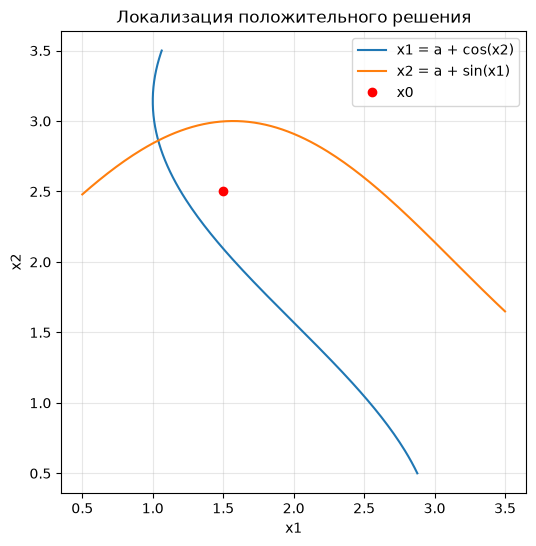

In [2]:
print("скан невязки ||F|| на сетке [0.5, 3.5]^2:")
best = None
grid = [0.5 + 0.25 * i for i in range(13)]
for x1 in grid:
    for x2 in grid:
        r = F([x1, x2])
        nrm = max(abs(r[0]), abs(r[1]))
        if best is None or nrm < best[0]:
            best = (nrm, x1, x2)
print(f"минимальная невязка на сетке: {best[0]:.4f} при ({best[1]}, {best[2]})")
print(f"x0 из файла: {x0}")

t = [0.5 + 0.02 * i for i in range(151)]
c1 = [a + math.cos(x2) for x2 in t]
c2 = [a + math.sin(x1) for x1 in t]
plt.figure(figsize=(6, 6))
plt.plot(c1, t, label="x1 = a + cos(x2)")
plt.plot(t, c2, label="x2 = a + sin(x1)")
plt.plot(x0[0], x0[1], "ro", label="x0")
plt.xlabel("x1")
plt.ylabel("x2")
plt.axis("equal")
plt.grid(True, alpha=0.3)
plt.legend()
plt.title("Локализация положительного решения")
plt.show()

## Метод простой итерации

$$
x_1^{(k+1)} = a + \cos x_2^{(k)},\quad
x_2^{(k+1)} = a + \sin x_1^{(k)}
$$

In [3]:
x_si, n_si, hist_si = simple_iteration(phi, x0, eps)
print("решение (простая итерация) =", fmt_vec(x_si))
print("итераций =", n_si)
print("F(x) =", fmt_vec(F(x_si)))
print("погрешность по итерациям (первые/последние):")
show = hist_si if len(hist_si) <= 20 else hist_si[:10] + hist_si[-5:]
idxs = list(range(1, len(hist_si) + 1))
if len(hist_si) > 20:
    idxs = list(range(1, 11)) + list(range(len(hist_si) - 4, len(hist_si) + 1))
for i, e in zip(idxs, show):
    print(f"  {i:3d}  {e:.6e}")

решение (простая итерация) = [1.0388774, 2.8618353]
итераций = 15
F(x) = [-1.6235694e-07, -4.7481183e-08]
погрешность по итерациям (первые/последние):
    1  4.974950e-01
    2  1.884923e-01
    3  8.459863e-02
    4  2.110958e-02
    5  1.082182e-02
    6  3.022345e-03
    7  1.530479e-03
    8  4.219088e-04
    9  2.140341e-04
   10  5.911307e-05
   11  2.998051e-05
   12  8.278024e-06
   13  4.198533e-06
   14  1.159314e-06
   15  5.879896e-07


## Метод Ньютона

In [4]:
x_nt, n_nt, hist_nt = newton(F, J, x0, eps)
print("решение (Ньютон) =", fmt_vec(x_nt))
print("итераций =", n_nt)
print("F(x) =", fmt_vec(F(x_nt)))
print("погрешность по итерациям:")
for i, e in enumerate(hist_nt, 1):
    print(f"  {i:3d}  {e:.6e}")

решение (Ньютон) = [1.0388775, 2.8618354]
итераций = 5
F(x) = [0, 0]
погрешность по итерациям:
    1  5.745571e-01
    2  1.085919e-01
    3  4.837862e-03
    4  7.638385e-06
    5  2.698575e-11


## Сравнение сходимости

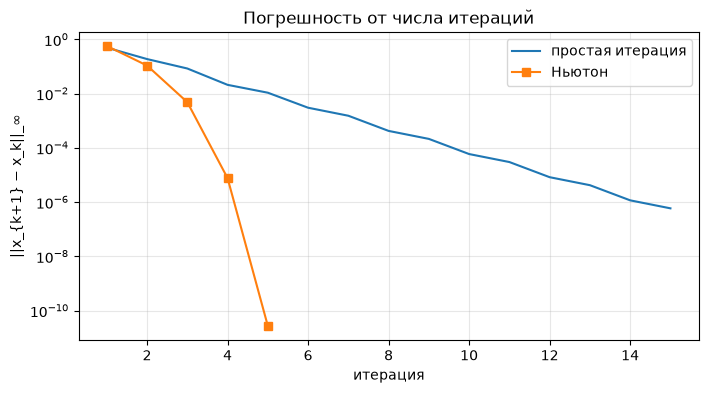

простая итерация: x = [1.0388774, 2.8618353], n = 15
Ньютон:           x = [1.0388775, 2.8618354], n = 5
оба компонента положительны: True


In [5]:
plt.figure(figsize=(8, 4))
plt.semilogy(range(1, len(hist_si) + 1), hist_si, "-", label="простая итерация")
plt.semilogy(range(1, len(hist_nt) + 1), hist_nt, "s-", label="Ньютон")
plt.xlabel("итерация")
plt.ylabel("||x_{k+1} − x_k||_∞")
plt.title("Погрешность от числа итераций")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

print(f"простая итерация: x = {fmt_vec(x_si)}, n = {n_si}")
print(f"Ньютон:           x = {fmt_vec(x_nt)}, n = {n_nt}")
print("оба компонента положительны:", x_si[0] > 0 and x_si[1] > 0)